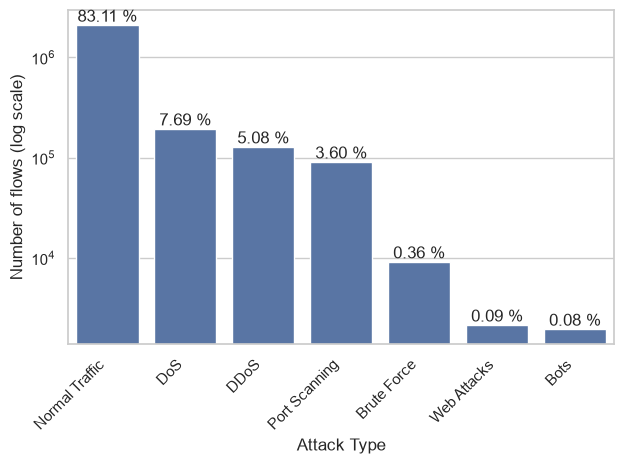

In [7]:
from typing import cast

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from matplotlib.container import BarContainer

#loading the dataset
df = pd.read_csv("cicids2017_cleaned.csv")
counts = df["Attack Type"].value_counts() / df.shape[0] * 100

#visualizing different types if traffic
ax = sns.countplot(x="Attack Type", data=df, order=counts.index)
ax.set_yscale("log")
bars = cast(BarContainer, ax.containers[0])
ax.bar_label(bars, labels=[f"{v:,.2f} %" for v in counts.values])
ax.set_ylabel("Number of flows (log scale)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

In [9]:
from matplotlib import colors
import numpy as np

def visualize_side_by_side(y_true, y_pred, labels, title=None):
    fig, axes = plt.subplots(1, 2, figsize=(22, 8))
    if title is not None:
        fig.suptitle(title, fontsize=18, fontweight='bold', y=0.98)

    # LEFT: per-class precision / recall / F1
    ax1 = axes[0]
    report = classification_report(
        y_true, y_pred, labels=labels, zero_division=0, output_dict=True
    )
    metrics = pd.DataFrame(report).T.loc[list(labels), ["precision", "recall", "f1-score"]]
    metrics.plot(kind="bar", ax=ax1, ylim=(0.7, 1.0), width=0.8)   # zoomed: 0.99 vs 1.00 is invisible at 0-1
    ax1.set_title("Performance by Class (y-axis starts at 0.7)", fontsize=14, fontweight='bold')
    ax1.set_ylabel("Score")
    ax1.set_xlabel("Attack Class")
    ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45, ha='right')
    ax1.legend(loc="lower right")
    ax1.spines[['top', 'right']].set_visible(False)

    # RIGHT: row-normalized confusion matrix (diagonal = recall), counts in each cell
    ax2 = axes[1]
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    cm_pct = cm / cm.sum(axis=1, keepdims=True)
    annot = np.array([
        [f"{c:,}\n{p:.1%}" if c > 0 else "" for c, p in zip(row_c, row_p)]
        for row_c, row_p in zip(cm, cm_pct)
    ])
    sns.heatmap(
        cm_pct, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1,
        xticklabels=labels, yticklabels=labels,
        cbar_kws={"label": "Fraction of actual class (recall)", "shrink": 0.8},
        ax=ax2
    )
    ax2.set_title("Confusion Matrix (row-normalized)", fontsize=14, pad=15, fontweight='bold')
    ax2.set_xlabel("Predicted Label", fontsize=12, labelpad=10)
    ax2.set_ylabel("Actual Label", fontsize=12, labelpad=10)
    ax2.set_xticklabels(ax2.get_xticklabels(), rotation=45, ha='right', fontsize=10)
    ax2.set_yticklabels(ax2.get_yticklabels(), rotation=0, fontsize=10)

    plt.tight_layout()
    plt.show()

In [10]:
X = df.drop(columns="Attack Type")
y = df["Attack Type"]


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [11]:
from sklearn.metrics import f1_score, precision_recall_fscore_support

X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.15,
                                            stratify=y_train, random_state=42)
counts = y_tr.value_counts()
schemes = {"balanced": "balanced",
           "sqrt": ((counts.max() / counts) ** 0.5).to_dict(),
           "none": None}

rows2 = []
for name, cw in schemes.items():
    m = RandomForestClassifier(n_estimators=100, class_weight=cw,
                               min_samples_leaf=2, n_jobs=-1, random_state=42).fit(X_tr, y_tr)
    p = m.predict(X_val)
    pr, rc, f, _ = precision_recall_fscore_support(y_val, p, labels=["Bots"])
    missed_attacks = ((y_val != "Normal Traffic") & (p == "Normal Traffic")).sum()
    false_alarms = ((y_val == "Normal Traffic") & (p != "Normal Traffic")).sum()
    rows2.append({"weights": name, "Bots precision": pr[0], "Bots recall": rc[0],
                  "Bots F1": f[0], "Missed Attacks": missed_attacks, "False Alarms": false_alarms,
                  "macro F1": f1_score(y_val, p, average="macro")})

,weights,Bots precision,Bots recall,Bots F1,Missed Attacks,False Alarms,macro F1
0,balanced,0.676,0.970,0.796,14,348,0.964
1,sqrt,0.744,0.906,0.817,52,247,0.969
2,none,0.893,0.786,0.836,135,149,0.972


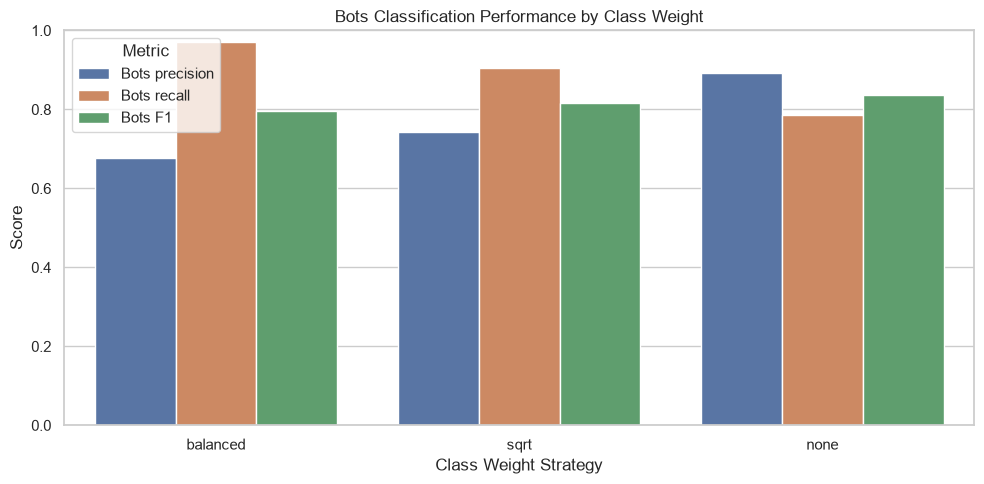

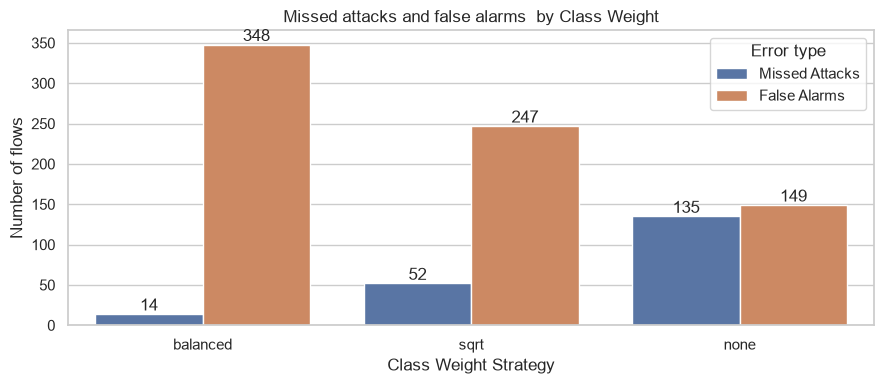

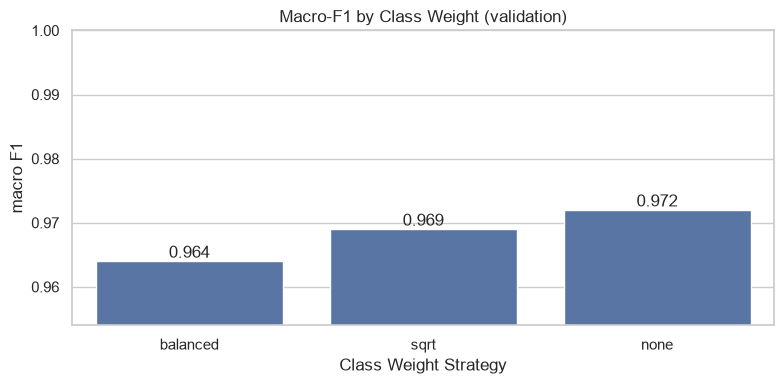

In [12]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

res = pd.DataFrame(rows2).round(3)   # "res", not "df": do not overwrite the dataset
display(res)

sns.set_theme(style="whitegrid")

# 1) Bots metrics by weighting scheme
res_melted = res.melt(
    id_vars="weights",
    value_vars=["Bots precision", "Bots recall", "Bots F1"],
    var_name="Metric",
    value_name="Score"
)
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=res_melted, x="weights", y="Score", hue="Metric")
ax.set_title("Bots Classification Performance by Class Weight")
ax.set_xlabel("Class Weight Strategy")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

# 2) Missed attacks vs false alarms
err_melted = res.melt(
    id_vars="weights",
    value_vars=["Missed Attacks", "False Alarms"],
    var_name="Error type",
    value_name="Number of flows"
)
plt.figure(figsize=(9, 4))
ax = sns.barplot(data=err_melted, x="weights", y="Number of flows", hue="Error type")
ax.set_title("Missed attacks and false alarms  by Class Weight")
ax.set_xlabel("Class Weight Strategy")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.show()

# 3) Macro-F1
plt.figure(figsize=(8, 4))
ax = sns.barplot(data=res, x="weights", y="macro F1")
ax.set_title("Macro-F1 by Class Weight (validation)")
ax.set_xlabel("Class Weight Strategy")
ax.set_ylim(res["macro F1"].min() - 0.01, 1)
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.show()

On choisit une pondération `w_i = sqrt(n_max / n_i)` pour compenser le déséquilibre des classes. La racine carrée atténue les poids extrêmes de la pondération complète (`balanced`) tout en favorisant le rappel des classes rares, prioritaire en détection d'intrusion (une attaque non détectée coûte plus cher qu'une fausse alerte). Le choix est comparé à `balanced` et `none` sur un jeu de validation (attaques manquées, fausses alertes, macro-F1 : graphiques ci-dessus).

In [13]:
counts = y_train.value_counts()
cw = ((counts.max() / counts) ** 0.5).to_dict()
rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight=cw,
    min_samples_leaf=2,
    n_jobs=-1,
    random_state=42
).fit(X_train, y_train)
print(classification_report(y_test, rf_model.predict(X_test), digits=3))

                precision    recall  f1-score   support

          Bots      0.703     0.884     0.784       389
   Brute Force      1.000     0.999     0.999      1830
          DDoS      1.000     1.000     1.000     25603
           DoS      0.997     0.999     0.998     38749
Normal Traffic      1.000     0.999     0.999    419012
 Port Scanning      0.989     0.999     0.994     18139
   Web Attacks      0.982     0.991     0.986       429

      accuracy                          0.999    504151
     macro avg      0.953     0.981     0.966    504151
  weighted avg      0.999     0.999     0.999    504151



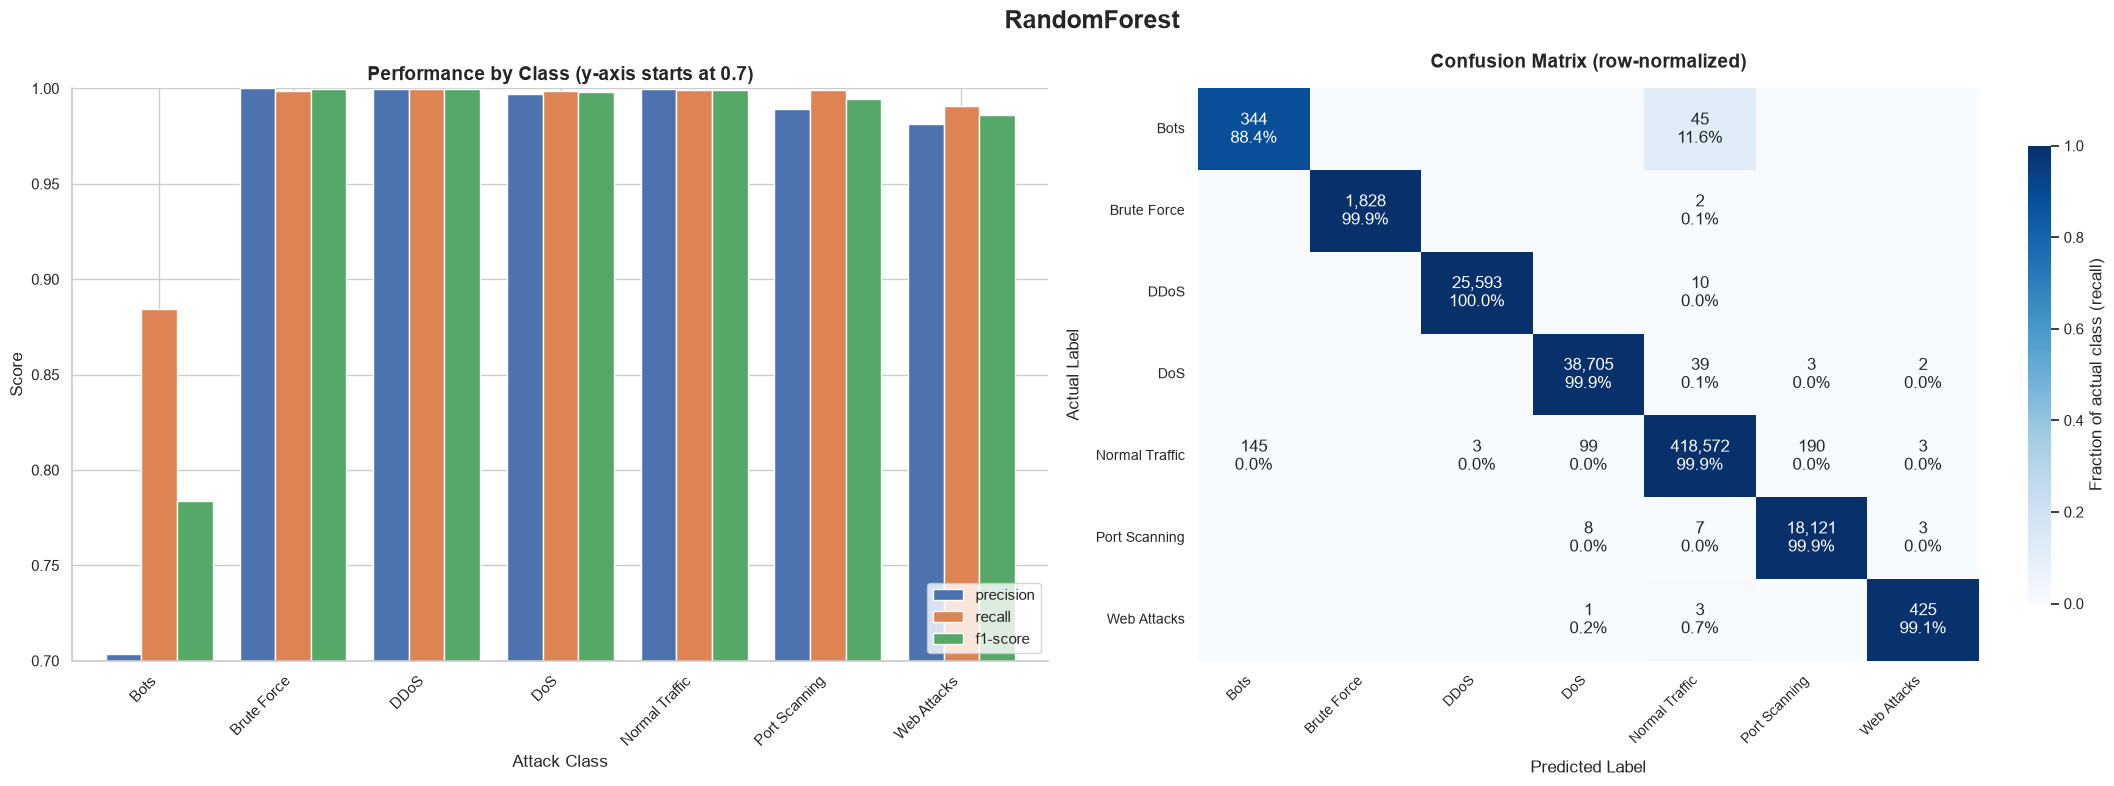

In [14]:
y_pred = rf_model.predict(X_test)
visualize_side_by_side(y_test, y_pred, rf_model.classes_, title="RandomForest")

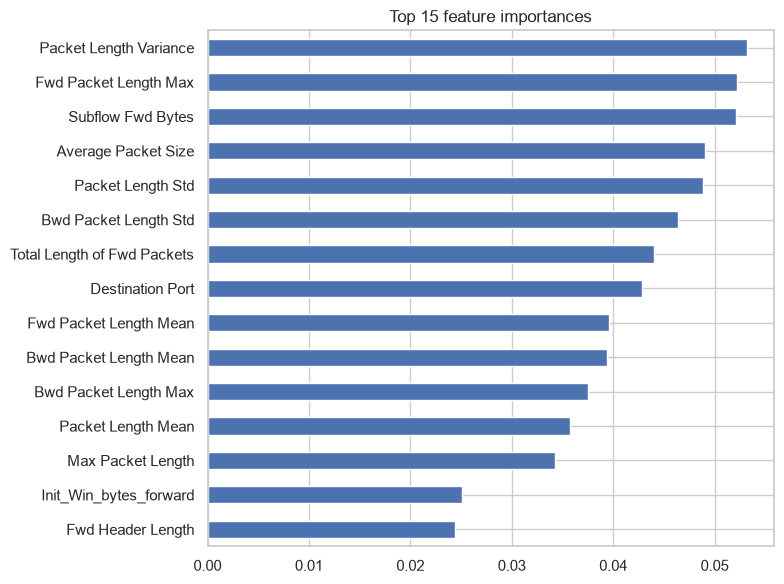

In [15]:
# 1) which features drive the model
imp = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)
imp.head(15).sort_values().plot.barh(figsize=(8, 6), title="Top 15 feature importances")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=200)
plt.show()

In [16]:
import joblib

# Save
joblib.dump({"model": rf_model, "features": list(X.columns)}, "random_forest.joblib", compress=3)

['random_forest.joblib']

In [17]:
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier

le = LabelEncoder()

y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

# Modèle 2 : XGBoost
xgb_model = XGBClassifier(
    objective="multi:softprob",
    eval_metric="mlogloss",

    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,

    subsample=0.8,
    colsample_bytree=0.8,

    min_child_weight=1,
    reg_lambda=1,

    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

# Same sqrt weights as the Random Forest (cw is computed on y_train only, cell above)
sw = y_train.map(cw).to_numpy()
xgb_model.fit(X_train, y_train_encoded, sample_weight=sw)

y_pred_encoded = xgb_model.predict(X_test)

y_pred_xgb = le.inverse_transform(y_pred_encoded.astype(int))

                precision    recall  f1-score   support

          Bots      0.687     0.954     0.799       389
   Brute Force      1.000     0.998     0.999      1830
          DDoS      1.000     1.000     1.000     25603
           DoS      0.998     1.000     0.999     38749
Normal Traffic      1.000     0.999     0.999    419012
 Port Scanning      0.989     0.999     0.994     18139
   Web Attacks      0.988     0.995     0.992       429

      accuracy                          0.999    504151
     macro avg      0.952     0.992     0.969    504151
  weighted avg      0.999     0.999     0.999    504151



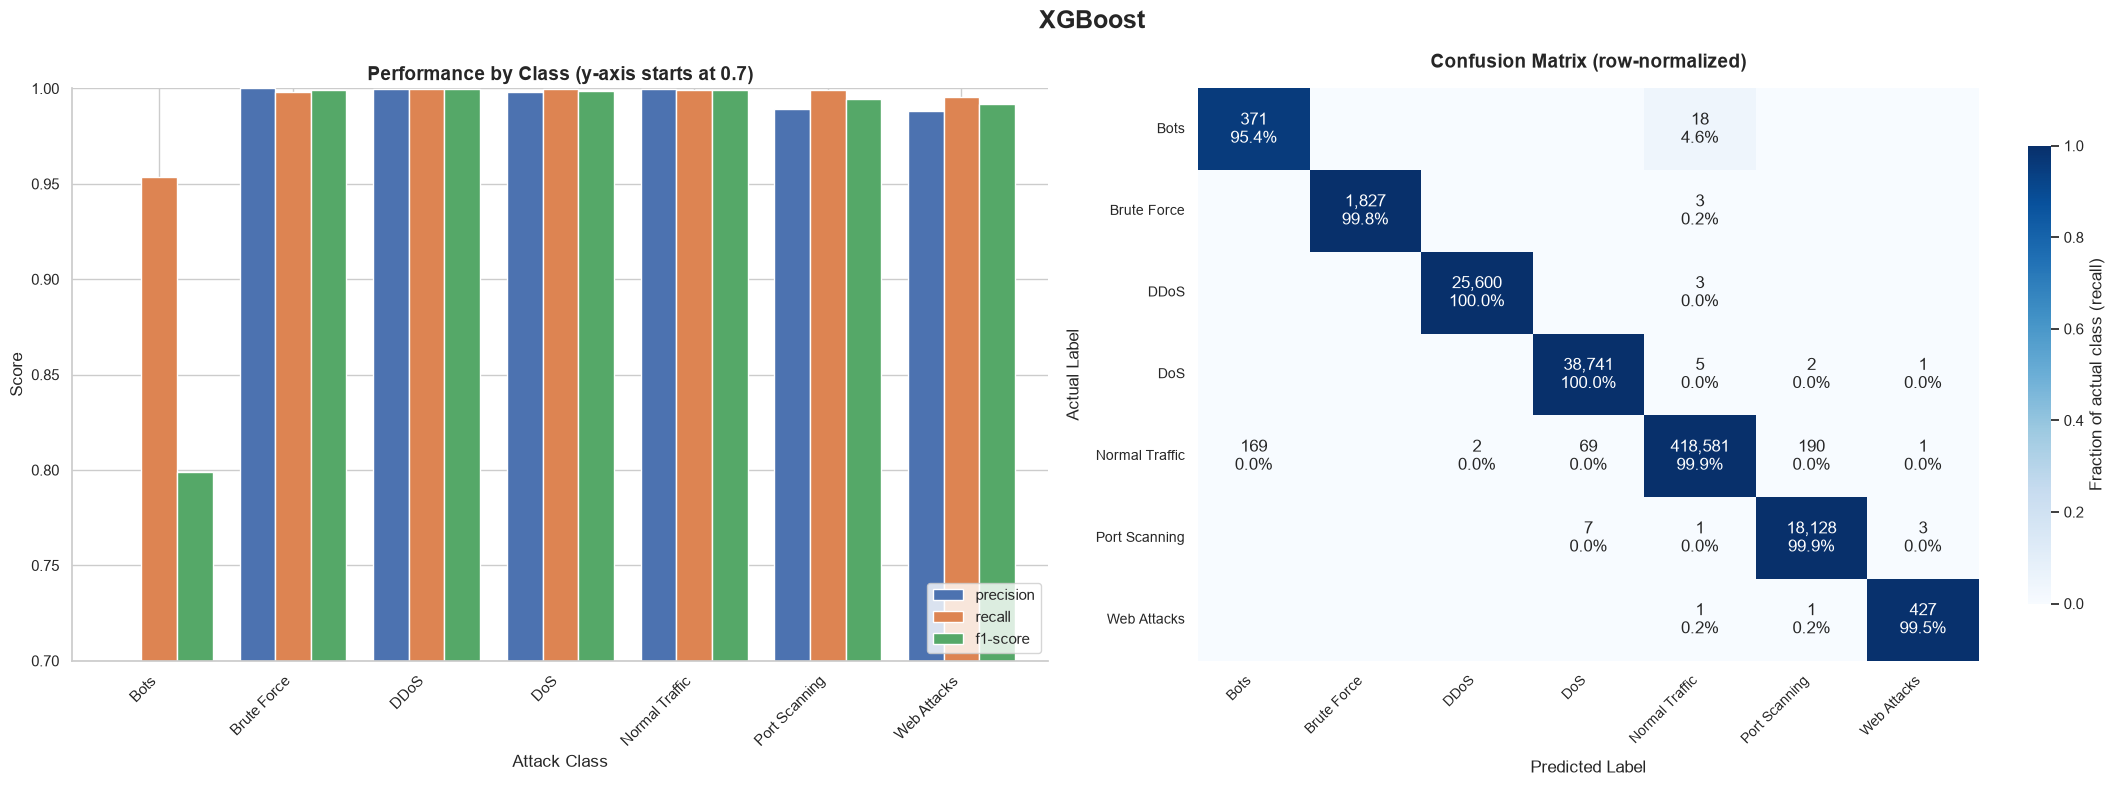

In [18]:
print(classification_report(y_test, y_pred_xgb, digits=3))
visualize_side_by_side(y_test, y_pred_xgb, le.classes_, title="XGBoost")

In [19]:
# Model selection on the VALIDATION split (X_tr / X_val from the weights experiment).
# The test set is only used afterwards, once, for the chosen model.
from sklearn.base import clone

cw_tr = ((y_tr.value_counts().max() / y_tr.value_counts()) ** 0.5).to_dict()
sw_tr = y_tr.map(cw_tr).to_numpy()

rf_val = RandomForestClassifier(n_estimators=200, class_weight=cw_tr,
                                min_samples_leaf=2, n_jobs=-1, random_state=42).fit(X_tr, y_tr)
xgb_val = clone(xgb_model).fit(X_tr, le.transform(y_tr), sample_weight=sw_tr)

def summarize(name, y_true, y_pred):
    yt, yp = np.asarray(y_true), np.asarray(y_pred)
    pr, rc, _, _ = precision_recall_fscore_support(yt, yp, labels=["Bots"], zero_division=0)
    return {
        "model": name,
        "FN (missed attacks)": int(((yt != "Normal Traffic") & (yp == "Normal Traffic")).sum()),
        "FA (false alarms)": int(((yt == "Normal Traffic") & (yp != "Normal Traffic")).sum()),
        "Bots precision": pr[0],
        "Bots recall": rc[0],
        "macro F1": f1_score(yt, yp, average="macro"),
    }

val_res = pd.DataFrame([
    summarize("Random Forest (sqrt)", y_val, rf_val.predict(X_val)),
    summarize("XGBoost (sqrt)", y_val, le.inverse_transform(xgb_val.predict(X_val).astype(int))),
]).round(3)
val_res

,model,FN (missed attacks),FA (false alarms),Bots precision,Bots recall,macro F1
0,Random Forest (sqrt),52,244,0.739,0.906,0.969
1,XGBoost (sqrt),18,242,0.703,0.949,0.969


In [20]:
import joblib

# Save XGBoost with its label encoder and feature list (same idea as random_forest.joblib)
joblib.dump({"model": xgb_model, "label_encoder": le, "features": list(X.columns)},
            "xgboost.joblib", compress=3)

['xgboost.joblib']

## Choix du modèle : Random Forest vs XGBoost

### Critère de sélection

En détection d'intrusion, un faux négatif (attaque classée comme trafic normal) est plus coûteux qu'une fausse alerte. Le critère principal est donc le **nombre d'attaques non détectées (FN)**. Les critères secondaires sont le nombre de **fausses alertes (FA)**, le **rappel et la précision de la classe Bots** et le **macro-F1**, qui donne le même poids à toutes les classes malgré le déséquilibre.

Les deux modèles utilisent les **mêmes poids de classes** (`w_i = sqrt(n_max / n_i)`) et sont comparés sur le **jeu de validation**. Le jeu de test n'est utilisé qu'ensuite, une seule fois, pour le modèle retenu.

### Comparaison sur le jeu de validation

| Critère | Random Forest | XGBoost |
|---|---:|---:|
| Attaques non détectées (FN) | 52 | **18** |
| Fausses alertes (FA) | 244 | 242 |
| Rappel Bots | 0.906 | **0.949** |
| Précision Bots | **0.739** | 0.703 |
| Macro-F1 | 0.969 | 0.969 |

### Décision

Modèle retenu : **XGBoost (sqrt)**.

Justification : XGBoost détecte davantage d'attaques, avec seulement 18 faux négatifs contre 52 pour Random Forest. Il améliore également le rappel de la classe Bots (0.949 contre 0.906), avec seulement deux fausses alertes de moins. Sa précision Bots est légèrement inférieure (0.703 contre 0.739), mais cette baisse est acceptable au regard du nombre d'attaques supplémentaires détectées. Les deux modèles obtiennent le même macro-F1 (0.969).

Compte tenu du coût plus élevé des attaques non détectées, XGBoost est donc retenu pour la suite de l'évaluation.